<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and data attribution](README.md)

# 01 · Snap shares have different denominators

Can a player have more than 100% participation? A player can take every offensive snap and also appear on special teams: the two reported percentages use different denominators. We will keep the units separate, then ask which players reach the same participation threshold in each unit.

**Historical 2025 season, week 1, Kansas City against the Chargers.** Default replay serves the complete, unmodified nflverse season Parquet asset captured on **2026-11-14 UTC**, with snap data originating from Pro Football Reference. The real worker selects Kansas City's rows. These are recorded observations, not synthetic values. Live mode retrieves the same historical asset; it can reflect later corrections. Snap participation is not touches, quality, health or a starter designation.

## Choose a unit-specific participation threshold

`DATA_MODE` accepts **"replay"** or **"live"**; live never falls back to the recording. `MIN_UNIT_SHARE` is a finite fraction from **0.1 to 1.0**, inclusive. A player qualifies separately for each unit when its **reported, rounded share is at least** the threshold. Default **0.50** means 50%; the experiment uses **0.80**.

The season, week and team stay fixed so the experiment changes only a local classification rule. A reported 0.80 may be a rounded value; it does not establish an exact unrounded 80% rate. Restart Kernel → Run All after editing.

In [1]:
DATA_MODE = "replay"  # "replay" or "live"; historical 2025 week 1, KC
MIN_UNIT_SHARE = 0.50  # Fraction, inclusive threshold; experiment: 0.80

In [2]:
import hashlib
import json
import math
import os
from datetime import UTC, datetime
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

from replay_source import ReplaySource, request_key

assert DATA_MODE in {"replay", "live"}
assert (
    isinstance(MIN_UNIT_SHARE, (int, float))
    and not isinstance(MIN_UNIT_SHARE, bool)
    and math.isfinite(MIN_UNIT_SHARE)
    and 0.1 <= MIN_UNIT_SHARE <= 1
)
manifest = json.loads(Path("fixtures/manifest.json").read_text())
env_keys = [
    "NFL_ESPN_SITE_URL",
    "NFL_ESPN_STANDINGS_URL",
    "NFL_ESPN_CORE_URL",
    "NFL_ESPN_COMMON_URL",
    "NFL_NFLVERSE_URL",
    "NFL_SLEEPER_URL",
]
previous_env = {key: os.environ.pop(key, None) for key in env_keys}
replay = ReplaySource(Path("fixtures")) if DATA_MODE == "replay" else None
if replay:
    os.environ["NFL_NFLVERSE_URL"] = replay.url
started = datetime.now(UTC)
colors = {"Offense": "#287d85", "Defense": "#a14d46", "Special teams": "#8a6ba8"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"Source: nflverse / Pro Football Reference · 2025 week 1 KC · {DATA_MODE} · retrieved {source_time}",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.92))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-nfl/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-nfl/notebooks/pyproject.toml.

## Download once, then inspect all three units

The literal Git-tag launch needs no local worker checkout. `snap_counts` downloads the **complete 2025 season file**, then filters week and team inside the worker. A SQL LIMIT would not bound that file download. An explicit season avoids a current-season lookup; this story needs no ESPN or Sleeper request. Materializing the result once prevents repeated retrieval while charting.

The long table preserves each player's offense, defense and special-teams observations separately. Missing measurements remain missing; explicit zero participation remains zero. The availability query reports both.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nfl' (
 TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-nfl@v0.2.0 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with httpx==0.28.1 --with httpx2==2.16.0 --with pyarrow==25.0.1 vgi-nfl'
);
CREATE TABLE snaps AS SELECT * FROM nfl.main.snap_counts(season:=2025,week:=1,team:='KC');
CREATE TABLE unit_snaps AS
SELECT pfr_player_id,player,'Offense' AS unit,1 AS bit,offense_snaps AS snaps,offense_pct AS reported_share FROM snaps
UNION ALL SELECT pfr_player_id,player,'Defense',2,defense_snaps,defense_pct FROM snaps
UNION ALL SELECT pfr_player_id,player,'Special teams',4,st_snaps,st_pct FROM snaps;

,Count


In [4]:
%%sql availability <<
SELECT unit,count(*) AS player_rows,
 count(*) FILTER(WHERE snaps IS NULL) AS missing_snap_count,
 count(*) FILTER(WHERE reported_share IS NULL) AS missing_share,
 count(*) FILTER(WHERE snaps=0) AS zero_snap_count,
 count(*) FILTER(WHERE snaps>0) AS positive_snap_count,
 sum(reported_share) AS sum_of_player_shares
FROM unit_snaps GROUP BY unit ORDER BY unit;

In [5]:
retrieved = datetime.now(UTC)
source_time = (manifest["capture_finished_utc"] if replay else retrieved.isoformat())[:19] + " UTC"
assert con.execute(
    "SELECT count(*)=count(DISTINCT pfr_player_id) AND count(*)>0 AND count(DISTINCT game_id)=1 FROM snaps"
).fetchone()[0]
assert (
    con.execute(
        "SELECT count(*) FROM snaps WHERE pfr_player_id IS NULL OR season<>2025 OR week<>1 OR team<>'KC'"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM unit_snaps WHERE snaps<0 OR reported_share<0 OR reported_share>1"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute("SELECT count(*) FROM unit_snaps").fetchone()[0]
    == 3 * con.execute("SELECT count(*) FROM snaps").fetchone()[0]
)
fingerprint = hashlib.sha256(
    json.dumps(
        con.execute("SELECT * FROM snaps ORDER BY pfr_player_id").fetchall(), separators=(",", ":")
    ).encode()
).hexdigest()
if replay:
    assert sorted(map(request_key, replay.requests)) == sorted(
        request_key(e["request_path"]) for e in manifest["entries"]
    )
    assert (
        con.execute(
            "SELECT * FROM snaps EXCEPT SELECT * EXCLUDE(pfr_game_id) FROM read_parquet('fixtures/snap-counts-2025.parquet') WHERE week=1 AND team='KC'"
        ).fetchall()
        == []
    )
    assert (
        con.execute(
            "SELECT * EXCLUDE(pfr_game_id) FROM read_parquet('fixtures/snap-counts-2025.parquet') WHERE week=1 AND team='KC' EXCEPT SELECT * FROM snaps"
        ).fetchall()
        == []
    )
    all_rows = con.execute(
        "SELECT count(*) FROM read_parquet('fixtures/snap-counts-2025.parquet')"
    ).fetchone()[0]
    request_note = f"Replay served **{len(replay.requests)} exact request** for the complete **{all_rows:,}-row, {manifest['entries'][0]['bytes']:,}-byte season file**. Every selected worker row agrees with its raw Parquet fields."
else:
    request_note = f"Live retrieval ran from **{started.isoformat()}** to **{retrieved.isoformat()}**. HTTP attempts are not instrumented; retries may occur."
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/request-audit.json").write_text(
    json.dumps(
        {
            "mode": DATA_MODE,
            "requests": replay.requests if replay else None,
            "fingerprint": fingerprint,
            "started_utc": started.isoformat(),
            "finished_utc": retrieved.isoformat(),
        },
        indent=2,
    )
)
display(availability)
game = con.execute("SELECT DISTINCT game_id,game_type,team,opponent FROM snaps").df()
display(game)
prose(
    f"{request_note} **{int(availability.player_rows.iloc[0])} players** each have three unit records. Summing shares across players is not a team percentage: multiple players participate on the same snap. Missing shares: **{int(availability.missing_share.sum())}**; missing counts: **{int(availability.missing_snap_count.sum())}**. Source time: **{source_time}**. Population fingerprint: `{fingerprint}`."
)

,unit,player_rows,missing_snap_count,missing_share,zero_snap_count,positive_snap_count,sum_of_player_shares
0,Defense,47,0,0,29,18,10.99
1,Offense,47,0,0,28,19,11.00
2,Special teams,47,0,0,14,33,11.00


,game_id,game_type,team,opponent
0,2025_01_KC_LAC,REG,KC,LAC


Replay served **1 exact request** for the complete **26,613-row, 242,046-byte season file**. Every selected worker row agrees with its raw Parquet fields. **47 players** each have three unit records. Summing shares across players is not a team percentage: multiple players participate on the same snap. Missing shares: **0**; missing counts: **0**. Source time: **2026-11-14T08:43:00 UTC**. Population fingerprint: `f8cce8df1603e0e3fcd03f565cf31677c4e1d1fdcbf7140b0dee124f3511f318`.

## A cross-unit sum has no whole-game denominator

The next query deliberately finds players whose three reported shares sum above one. That diagnostic exposes why the percentages must not be stacked into a whole-game participation chart. It does **not** flag an invalid record.

Show at most six examples alphabetically, using a local display limit after retrieval. Each panel has its own unit denominator and the same 0–100% scale. Labels give that unit's snap count. The examples and raw population stay unchanged when we alter the threshold.

In [6]:
%%sql
CREATE TABLE examples AS
SELECT pfr_player_id,player FROM snaps
WHERE offense_pct+defense_pct+st_pct>1
ORDER BY player,pfr_player_id LIMIT 6;

,Count


**10 players** have a cross-unit sum above 100%; the chart shows **6 alphabetical examples**. This combines distinct denominators, so the sum is not a whole-game participation rate.

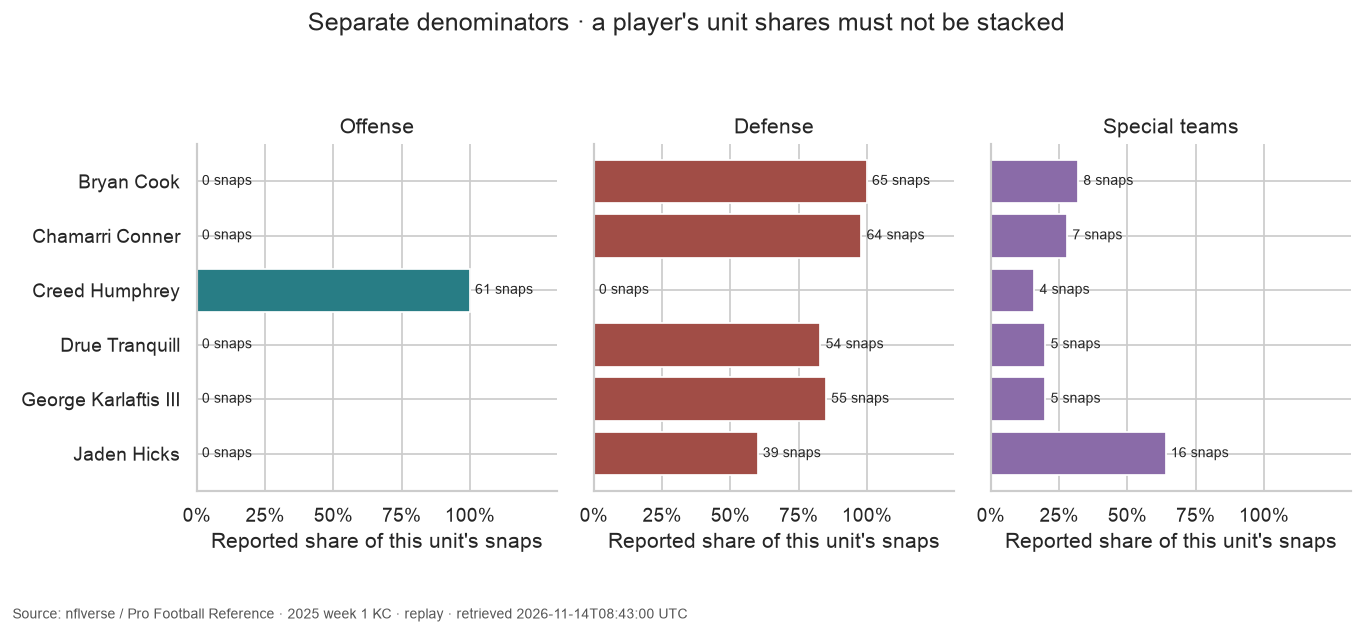

In [7]:
example_rows = con.execute(
    "SELECT u.* FROM unit_snaps u JOIN examples e USING(pfr_player_id) ORDER BY player,bit"
).df()
example_names = con.execute("SELECT player FROM examples ORDER BY player,pfr_player_id").df().player.tolist()
above_one = con.execute("SELECT count(*) FROM snaps WHERE offense_pct+defense_pct+st_pct>1").fetchone()[0]
prose(
    f"**{above_one} players** have a cross-unit sum above 100%; the chart shows **{len(example_names)} alphabetical examples**. This combines distinct denominators, so the sum is not a whole-game participation rate."
)
if example_names:
    fig, axes = plt.subplots(1, 3, figsize=(11, 5), sharex=True, sharey=True)
    for ax, unit in zip(axes, colors, strict=True):
        rows = example_rows[example_rows.unit == unit].set_index("player").reindex(example_names)
        bars = ax.barh(example_names, rows.reported_share, color=colors[unit])
        ax.bar_label(
            bars,
            labels=[
                f"{int(r.snaps)} snaps" if pd.notna(r.snaps) else "count unavailable"
                for r in rows.itertuples()
            ],
            padding=3,
            fontsize=8,
        )
        ax.set(title=unit, xlabel="Reported share of this unit's snaps", xlim=(0, 1.32))
        ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
        ax.xaxis.set_major_formatter(PercentFormatter(1))
    axes[0].invert_yaxis()
    fig.suptitle("Separate denominators · a player's unit shares must not be stacked")
    finish(fig)
else:
    prose("No cross-unit sum above 100% in this retrieval; the illustrative chart is omitted.")

## Count memberships and distinct players separately

Apply the threshold independently to all three units. A player can qualify for more than one unit; adding unit counts can therefore double-count people. Encode the exact combination, including **no unit reaches the threshold**, then count each player once.

Missing shares are never treated as zero: the SQL retains an explicit unavailable category. The eight known combinations remain visible even when their count is zero. `minimum_qualifying_snaps` also shows why the same percentage can correspond to different workloads across units.

In [8]:
%%sql
CREATE TABLE qualifying AS
SELECT *,reported_share>={{MIN_UNIT_SHARE}} AS qualifies FROM unit_snaps;
CREATE TABLE player_membership AS
SELECT pfr_player_id,player,
 CASE WHEN count(*) FILTER(WHERE reported_share IS NULL)>0 THEN NULL
 ELSE sum(CASE WHEN qualifies THEN bit ELSE 0 END) END AS mask
FROM qualifying GROUP BY pfr_player_id,player;
CREATE TABLE groups AS
SELECT m.mask,m.label,count(p.pfr_player_id) AS players
FROM (VALUES
 (0,'No unit reaches threshold'),(1,'Offense only'),(2,'Defense only'),(4,'Special teams only'),
 (3,'Offense + defense'),(5,'Offense + special teams'),(6,'Defense + special teams'),(7,'All three'),
 (NULL,'Unavailable unit share')
) m(mask,label)
LEFT JOIN player_membership p ON p.mask IS NOT DISTINCT FROM m.mask
GROUP BY m.mask,m.label;

,Count


In [9]:
%%sql unit_summary <<
SELECT unit,count(*) FILTER(WHERE qualifies) AS qualifying_memberships,
 min(snaps) FILTER(WHERE qualifies) AS minimum_qualifying_snaps,
 max(snaps) FILTER(WHERE qualifies) AS maximum_qualifying_snaps
FROM qualifying GROUP BY unit ORDER BY unit;

,unit,qualifying_memberships,minimum_qualifying_snaps,maximum_qualifying_snaps
0,Defense,11,38,65
1,Offense,11,31,61
2,Special teams,8,16,21


At **50%**, there are **30 qualifying unit memberships**, and **29 distinct players** in a fully observed qualifying combination. **18 players** reach none of the thresholds; **0** have an unavailable classification. A player can appear in multiple unit counts, but appears once in this combination chart. No conclusion about quality or touches follows from membership.

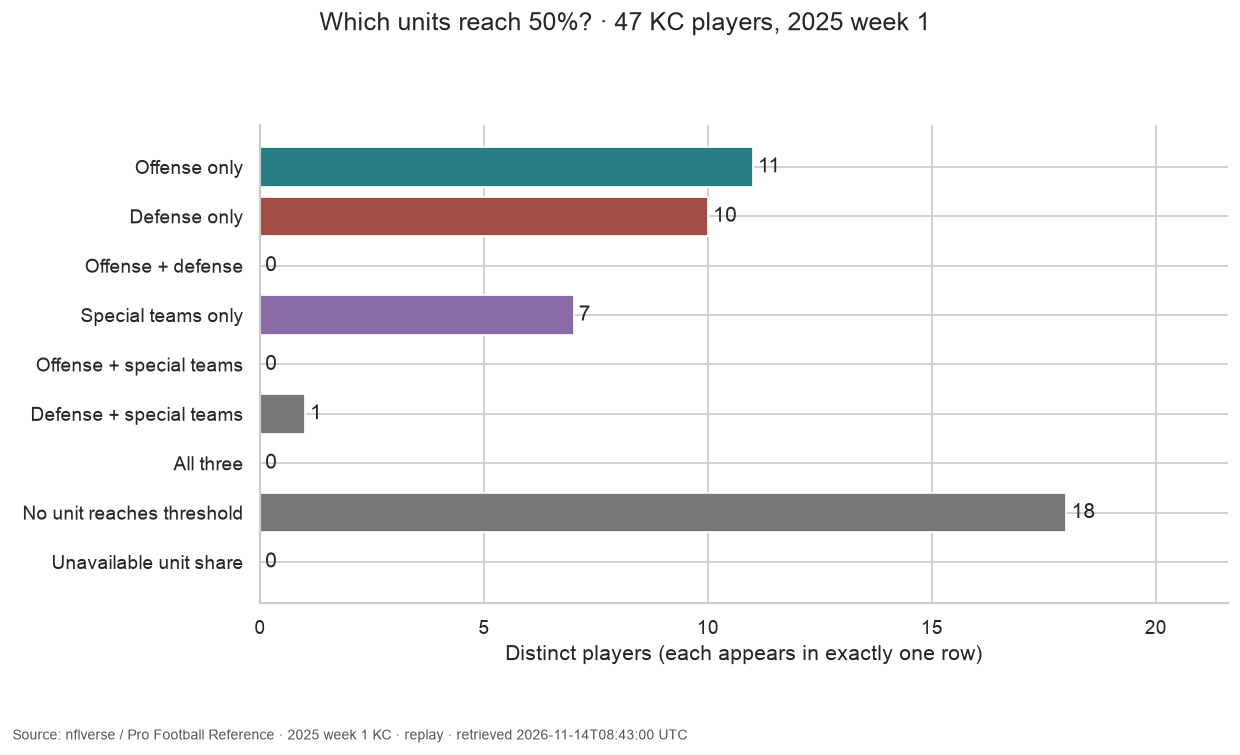

In [10]:
display(unit_summary)
groups = con.execute(
    "SELECT * FROM groups ORDER BY CASE WHEN mask IS NULL THEN 9 WHEN mask=0 THEN 8 ELSE mask END"
).df()
assert groups.players.sum() == con.execute("SELECT count(*) FROM snaps").fetchone()[0]
assert (
    con.execute(
        "SELECT count(*) FROM qualifying WHERE qualifies IS DISTINCT FROM (reported_share>=?)",
        [MIN_UNIT_SHARE],
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT coalesce(sum(bit_count(mask)),0) FROM player_membership WHERE mask IS NOT NULL"
    ).fetchone()[0]
    == con.execute(
        "SELECT count(*) FROM qualifying q JOIN player_membership p USING(pfr_player_id) WHERE p.mask IS NOT NULL AND q.qualifies"
    ).fetchone()[0]
)
unique_players = con.execute("SELECT count(*) FROM player_membership WHERE mask>0").fetchone()[0]
no_units = con.execute("SELECT count(*) FROM player_membership WHERE mask=0").fetchone()[0]
missing = con.execute("SELECT count(*) FROM player_membership WHERE mask IS NULL").fetchone()[0]
memberships = int(unit_summary.qualifying_memberships.sum())
prose(
    f"At **{MIN_UNIT_SHARE:.0%}**, there are **{memberships} qualifying unit memberships**, and **{unique_players} distinct players** in a fully observed qualifying combination. **{no_units} players** reach none of the thresholds; **{missing}** have an unavailable classification. A player can appear in multiple unit counts, but appears once in this combination chart. No conclusion about quality or touches follows from membership."
)
fig, ax = plt.subplots(figsize=(10, 6))
bar_colors = [
    {1: colors["Offense"], 2: colors["Defense"], 4: colors["Special teams"]}.get(int(r.mask), "#777777")
    if pd.notna(r.mask)
    else "#777777"
    for r in groups.itertuples()
]
bars = ax.barh(groups.label, groups.players, color=bar_colors)
ax.bar_label(bars, fmt="%d", padding=3)
ax.invert_yaxis()
ax.set(
    xlabel="Distinct players (each appears in exactly one row)", xlim=(0, max(1, groups.players.max()) * 1.2)
)
ax.xaxis.get_major_locator().set_params(integer=True)
fig.suptitle(f"Which units reach {MIN_UNIT_SHARE:.0%}? · {int(groups.players.sum())} KC players, 2025 week 1")
finish(fig)

## Experiment: raise the threshold to 80%

Keep `DATA_MODE="replay"` and change only `MIN_UNIT_SHARE` from **0.50 to 0.80**. Predict that no unit can gain members; the number of distinct qualifying players can only stay the same or fall. Compare the three unit counts, exact combinations, and no-unit group. A player can move from a two-unit combination into a one-unit combination as the rule tightens.

The raw fingerprint, availability table and separate-unit example chart must stay unchanged. The different minimum qualifying snap counts show that one percentage is not a shared workload denominator. Restore **0.50** afterwards. This is sensitivity of an illustrative participation rule in one game, not a recommended cutoff or a player-performance ranking.

In [11]:
con.close()
if replay:
    replay.close()
for key, value in previous_env.items():
    if value is None:
        os.environ.pop(key, None)
    else:
        os.environ[key] = value

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)